# Analyse du data drift en production

**Projet 8 – Prêt à Dépenser · modèle LightGBM `scoring_credit` v32**

**Objectif :** comparer les données **reçues par l'API en production** aux **données d'entraînement**
du modèle, pour détecter une dérive (*data drift*) qui pourrait rendre ses prédictions moins fiables.

**Plan :**
1. Chargement des données de production et de référence
2. Santé opérationnelle de l'API (erreurs, latence)
3. Dérive des scores prédits (PSI)
4. Dérive des variables d'entrée (Evidently)
5. Analyse par périodes : *quand* la dérive apparaît-elle ?
6. Zoom sur les variables en dérive
7. Impact métier : le taux de refus
8. Conclusions et points de vigilance

**Données analysées :** 2 000 demandes envoyées à l'API (`python -m scripts.simulate_traffic --in-process --n 2000`).
Les 1 000 premières sont des dossiers réels du jeu de test ; les 1 000 suivantes dérivent
progressivement (clients plus jeunes, `EXT_SOURCE_2/3` plus bas, revenus plus faibles, crédits plus
élevés). Environ 3 % des requêtes sont volontairement invalides.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from monitoring.analysis import load_logs, expand_inputs, load_reference, psi, operational_metrics, META, CATEGORICAL
from monitoring.drift_analysis import run_evidently

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REF_COLOR, PROD_COLOR = "#8A94A6", "#2563EB"
SEUIL = META["threshold"]
print(f"Modèle {META['version']} ({META['algorithm']}) · seuil métier = {SEUIL}")

Modèle v32 (LGBMClassifier) · seuil métier = 0.52


## 1. Chargement des données

- **Production** : chaque appel à l'API est enregistré dans la base SQLite `data/predictions.db`
  (dossier reçu, score, décision, temps de réponse, erreur éventuelle).
- **Référence** : 5 000 dossiers du jeu d'entraînement avec leurs scores (`model/reference_data.parquet`).
- On compare les **15 variables les plus importantes** du modèle, plus le score.

In [2]:
logs = load_logs(ROOT / "data" / "predictions.db")       # tous les appels (réussis et en erreur)
current = expand_inputs(logs)                              # dossiers des appels réussis + score
reference = load_reference()

print(f"Appels enregistrés : {len(logs)}  |  réussis : {len(current)}  |  référence : {len(reference)}")
print("Variables surveillées :", ", ".join(META["monitored_features"]))
logs[["timestamp", "endpoint", "status_code", "score", "decision", "model_version", "backend", "latency_ms"]].tail()

Appels enregistrés : 2000  |  réussis : 1942  |  référence : 5000
Variables surveillées : EXT_SOURCE_3, EXT_SOURCE_2, EXT_SOURCE_1, AMT_CREDIT, DAYS_BIRTH, PREV_CNT_PAYMENT_MEAN, BUREAU_DAYS_CREDIT_MAX, INST_PAYMENT_DIFF_MEAN, AMT_GOODS_PRICE, DAYS_EMPLOYED, AMT_ANNUITY, INST_AMT_PAYMENT_MEAN, POS_COUNT, INST_DAYS_LATE_MAX, BUREAU_DAYS_CREDIT_MIN


,timestamp,endpoint,status_code,score,decision,model_version,backend,latency_ms
1995,2026-11-12 11:34:52.805322+00:00,/predict,200,0.786291,REFUSE,v32,onnx,0.721541
1996,2026-11-12 11:34:52.813404+00:00,/predict,200,0.775527,REFUSE,v32,onnx,0.657379
1997,2026-11-12 11:34:52.821115+00:00,/predict,200,0.222530,ACCORDE,v32,onnx,0.488651
1998,2026-11-12 11:34:52.827997+00:00,/predict,200,0.694023,REFUSE,v32,onnx,0.453516
1999,2026-11-12 11:34:52.835816+00:00,/predict,200,0.416384,ACCORDE,v32,onnx,0.639961


## 2. Santé opérationnelle de l'API

Avant de parler de drift, on vérifie que l'API fonctionne bien : taux d'erreur et temps de réponse.

In [3]:
ops = operational_metrics(logs)
pd.Series({
    "Requêtes": ops["n_requests"],
    "Taux d'erreur": f"{ops['error_rate']:.1%}",
    "Latence API p50 / p95 (ms)": f"{ops['latency_p50_ms']:.2f} / {ops['latency_p95_ms']:.2f}",
    "Inférence p50 / p95 (ms)": f"{ops['inference_p50_ms']:.2f} / {ops['inference_p95_ms']:.2f}",
}, name="Valeur").to_frame()

,Valeur
Requêtes,2000
Taux d'erreur,2.9%
Latence API p50 / p95 (ms),0.63 / 0.92
Inférence p50 / p95 (ms),0.41 / 0.67


Codes HTTP : {200: 1942, 422: 58}


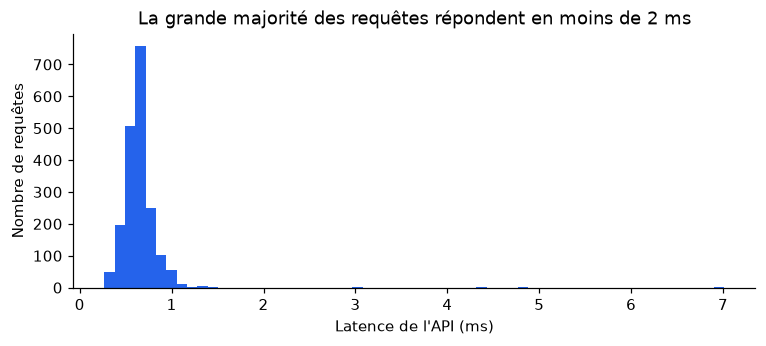

In [4]:
print("Codes HTTP :", logs["status_code"].value_counts().to_dict())
ok = logs[logs["status_code"] == 200]
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(ok["latency_ms"], bins=60, color=PROD_COLOR)
ax.set_xlabel("Latence de l'API (ms)"); ax.set_ylabel("Nombre de requêtes")
ax.set_title("La grande majorité des requêtes répondent en moins de 2 ms")
plt.show()

**Lecture :** les erreurs sont toutes des **422** (données invalides refusées par la validation),
ce qui correspond aux ~3 % de requêtes invalides envoyées volontairement. Aucune erreur 500 :
l'API est stable. La latence est très faible grâce à l'optimisation NumPy + ONNX.

## 3. Dérive des scores prédits

Si la population change, les scores du modèle changent aussi. On compare la distribution des
scores en production à celle de l'entraînement, avec le **PSI** (*Population Stability Index*) :

| PSI | Interprétation |
|---|---|
| < 0,1 | stable |
| 0,1 à 0,2 | à surveiller |
| > 0,2 | dérive significative |

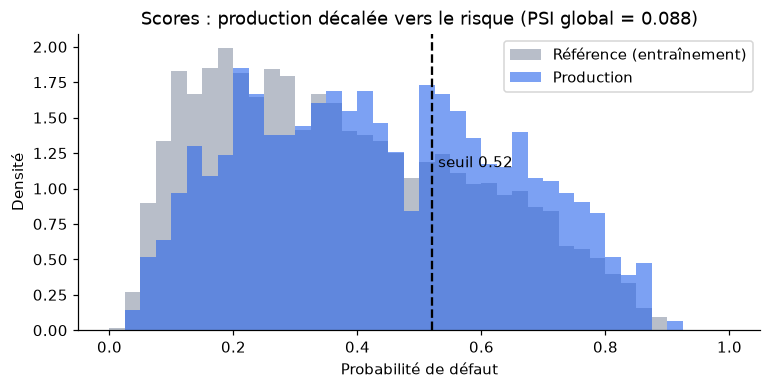

PSI global du score : 0.088


In [5]:
psi_score = psi(reference["score"].to_numpy(), current["score"].to_numpy())
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 41)
ax.hist(reference["score"], bins=bins, density=True, alpha=.6, color=REF_COLOR, label="Référence (entraînement)")
ax.hist(current["score"], bins=bins, density=True, alpha=.6, color=PROD_COLOR, label="Production")
ax.axvline(SEUIL, color="black", ls="--", lw=1.5); ax.text(SEUIL + .01, ax.get_ylim()[1] * .55, f"seuil {SEUIL}")
ax.set_xlabel("Probabilité de défaut"); ax.set_ylabel("Densité"); ax.legend()
ax.set_title(f"Scores : production décalée vers le risque (PSI global = {psi_score:.3f})")
plt.show()
print(f"PSI global du score : {psi_score:.3f}")

**Lecture :** la production est décalée vers la droite, au-delà du seuil. Pourtant, le **PSI global
reste sous 0,1** : sur l'ensemble de la période, on conclurait à tort que tout est stable. La partie 5
montre pourquoi.

## 4. Dérive des variables d'entrée (Evidently)

**Evidently** compare chaque variable entre la référence et la production. Pour des variables
numériques, il utilise la **distance de Wasserstein normalisée** : au-delà de **0,1**, la variable est
déclarée en dérive. Le rapport HTML complet est enregistré dans `monitoring/reports/`.

In [6]:
REPORTS = ROOT / "monitoring" / "reports"; REPORTS.mkdir(parents=True, exist_ok=True)
drift = run_evidently(reference, current, REPORTS / "drift_report_notebook.html")
table = (pd.DataFrame(drift["columns"]).T[["value", "threshold", "drift"]]
         .rename(columns={"value": "distance", "threshold": "seuil", "drift": "dérive"})
         .sort_values("distance", ascending=False))
print(f"Part des variables en dérive : {drift['drift_share']:.0%} ({table['dérive'].sum()} sur {len(table)})")
table

Part des variables en dérive : 31% (5 sur 16)


,distance,seuil,dérive
EXT_SOURCE_3,0.3576,0.1,True
EXT_SOURCE_2,0.3297,0.1,True
AMT_CREDIT,0.2749,0.1,True
score,0.2739,0.1,True
DAYS_BIRTH,0.2145,0.1,True
POS_COUNT,0.088,0.1,False
AMT_ANNUITY,0.0773,0.1,False
AMT_GOODS_PRICE,0.0561,0.1,False
BUREAU_DAYS_CREDIT_MAX,0.0519,0.1,False
PREV_CNT_PAYMENT_MEAN,0.0486,0.1,False


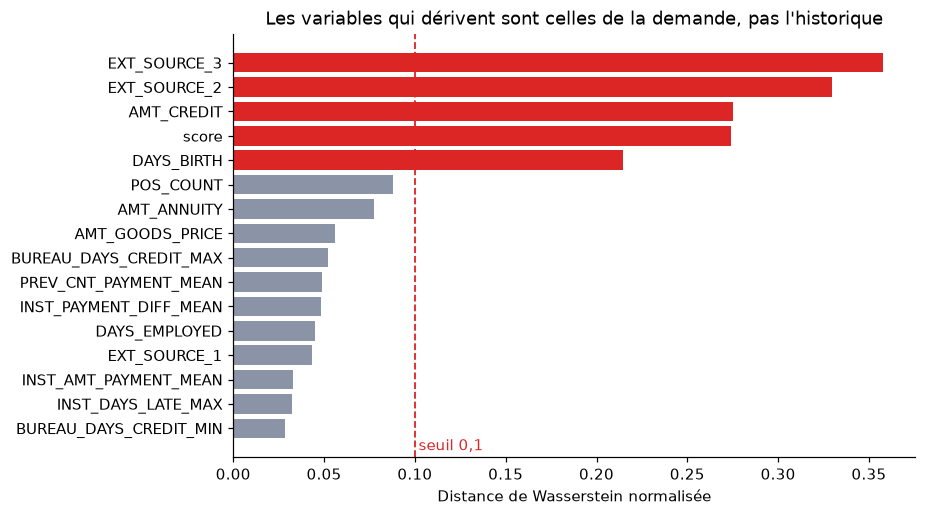

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#DC2626" if d else REF_COLOR for d in table["dérive"]]
ax.barh(table.index[::-1], table["distance"][::-1], color=colors[::-1])
ax.axvline(0.1, color="#DC2626", ls="--", lw=1.2); ax.text(0.102, -0.9, "seuil 0,1", color="#DC2626")
ax.set_xlabel("Distance de Wasserstein normalisée")
ax.set_title("Les variables qui dérivent sont celles de la demande, pas l'historique")
plt.show()

**Lecture :** 5 colonnes sur 16 dérivent : `EXT_SOURCE_3`, `EXT_SOURCE_2`, `AMT_CREDIT`,
`DAYS_BIRTH` et le `score`. Ce sont exactement les variables modifiées par la simulation.
Les variables d'historique (bureau, paiements, demandes précédentes) restent stables : la détection
est fiable.

## 5. Analyse par périodes : quand la dérive apparaît-elle ?

On découpe les 1 942 requêtes réussies en **4 périodes successives** d'environ 485 requêtes,
et on refait l'analyse sur chacune.

In [8]:
rows = []
for i, idx in enumerate(np.array_split(np.arange(len(current)), 4), start=1):
    w = current.iloc[idx]
    d = run_evidently(reference, w)
    rows.append({"période": i, "requêtes": len(w),
                 "variables en dérive": f"{d['drift_share']:.0%}",
                 "PSI du score": round(psi(reference['score'].to_numpy(), w['score'].to_numpy()), 3),
                 "score moyen": round(w["score"].mean(), 3),
                 "taux de refus": f"{(w['score'] >= SEUIL).mean():.1%}",
                 "colonnes en dérive": ", ".join(c for c, v in d["columns"].items() if v["drift"])})
windows = pd.DataFrame(rows).set_index("période")
windows

,requêtes,variables en dérive,PSI du score,score moyen,taux de refus,colonnes en dérive
période,,,,,,
1,486,6%,0.025,0.391,29.2%,POS_COUNT
2,486,19%,0.050,0.371,26.7%,"EXT_SOURCE_1, BUREAU_DAYS_CREDIT_MAX, INST_PAY..."
3,485,38%,0.182,0.456,39.2%,"EXT_SOURCE_3, EXT_SOURCE_2, EXT_SOURCE_1, AMT_..."
4,485,44%,1.618,0.527,51.8%,"EXT_SOURCE_3, EXT_SOURCE_2, EXT_SOURCE_1, AMT_..."


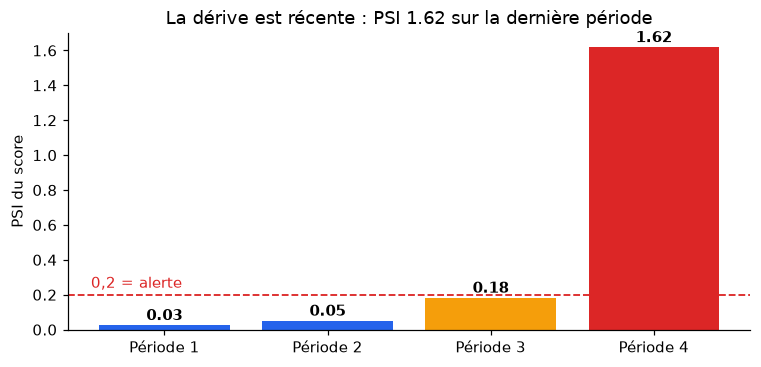

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
vals = windows["PSI du score"]
ax.bar([f"Période {i}" for i in vals.index], vals, color=["#2563EB", "#2563EB", "#F59E0B", "#DC2626"])
ax.axhline(0.2, color="#DC2626", ls="--", lw=1.2); ax.text(-0.45, 0.24, "0,2 = alerte", color="#DC2626")
for i, v in enumerate(vals): ax.text(i, v + 0.03, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_ylabel("PSI du score"); ax.set_title(f"La dérive est récente : PSI {vals.iloc[-1]:.2f} sur la dernière période")
plt.show()

**Lecture :** les périodes 1 et 2 sont stables (PSI ≤ 0,05). La dérive commence en période 3
(0,18, zone « à surveiller ») et explose en période 4 (**1,62**). Le PSI global de 0,09 **masquait**
cette dérive récente, diluée dans les données normales.

**Conclusion méthodologique :** le monitoring doit se faire sur des **fenêtres glissantes**,
pas sur l'ensemble des données cumulées.

On remarque aussi 1 à 3 variables « en dérive » dans les périodes 1 et 2, alors que rien n'a changé :
c'est du **bruit d'échantillonnage** (environ 485 requêtes par période). Il ne faut donc pas alerter
sur une variable isolée.

## 6. Zoom sur les variables en dérive

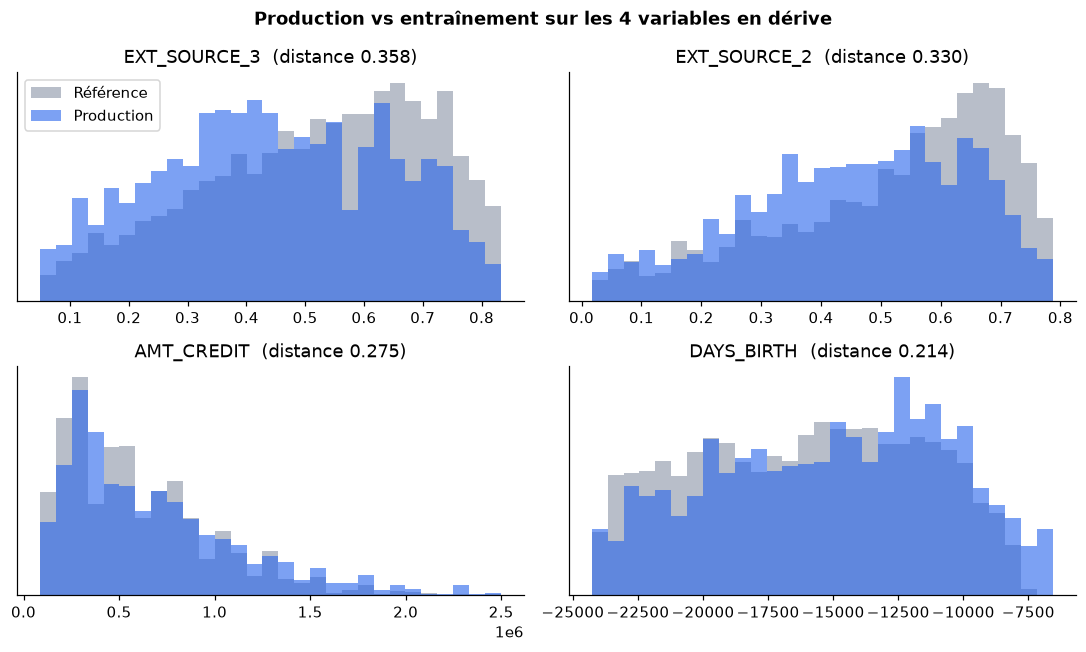

In [10]:
feats = ["EXT_SOURCE_3", "EXT_SOURCE_2", "AMT_CREDIT", "DAYS_BIRTH"]
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, f in zip(axes.ravel(), feats):
    r, c = pd.to_numeric(reference[f]).dropna(), pd.to_numeric(current[f]).dropna()
    bins = np.linspace(min(r.quantile(.01), c.quantile(.01)), max(r.quantile(.99), c.quantile(.99)), 30)
    ax.hist(r, bins=bins, density=True, alpha=.6, color=REF_COLOR, label="Référence")
    ax.hist(c, bins=bins, density=True, alpha=.6, color=PROD_COLOR, label="Production")
    ax.set_title(f"{f}  (distance {drift['columns'][f]['value']:.3f})"); ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Production vs entraînement sur les 4 variables en dérive", fontweight="bold")
plt.tight_layout(); plt.show()

**Lecture :**
- `EXT_SOURCE_3` et `EXT_SOURCE_2` : la production est décalée **vers les valeurs basses**.
  Ces scores externes sont les variables les plus importantes du modèle, d'où l'effet fort sur le score.
- `AMT_CREDIT` : des crédits demandés plus élevés.
- `DAYS_BIRTH` : des clients plus jeunes (valeurs moins négatives).

## 7. Impact métier : le taux de refus

Le data drift n'est pas qu'un indicateur technique : il change les décisions prises.

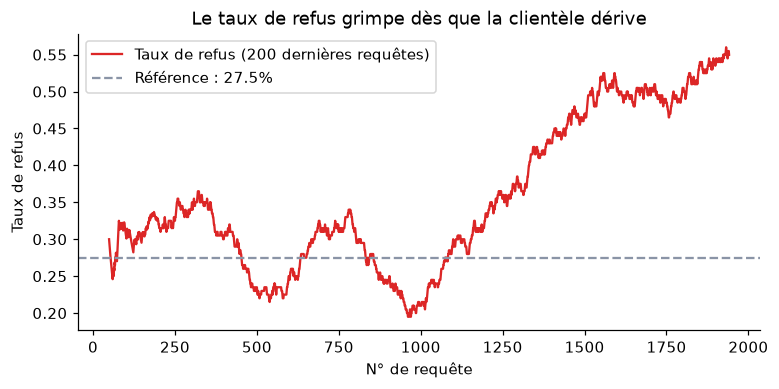

Taux de refus : référence 27.5%  ->  production 36.7%


In [11]:
ref_refusal = (reference["score"] >= SEUIL).mean()
s = current["score"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot((s >= SEUIL).rolling(200, min_periods=50).mean(), color="#DC2626", label="Taux de refus (200 dernières requêtes)")
ax.axhline(ref_refusal, color=REF_COLOR, ls="--", label=f"Référence : {ref_refusal:.1%}")
ax.set_xlabel("N° de requête"); ax.set_ylabel("Taux de refus"); ax.legend()
ax.set_title("Le taux de refus grimpe dès que la clientèle dérive")
plt.show()
print(f"Taux de refus : référence {ref_refusal:.1%}  ->  production {(s >= SEUIL).mean():.1%}")

## 8. Conclusions et points de vigilance

**Ce que montre l'analyse :**
1. **L'API est saine** : pas d'erreur 500, latence de l'ordre de la milliseconde, et les 422
   correspondent aux requêtes invalides.
2. **Une dérive est bien détectée** sur 5 colonnes sur 16, et ce sont les bonnes variables
   (`EXT_SOURCE_2/3`, `AMT_CREDIT`, `DAYS_BIRTH`, `score`).
3. **Le PSI global (≈ 0,09) cache une dérive récente** (PSI ≈ 1,6 sur la dernière période) :
   il faut surveiller par **périodes glissantes**.
4. **L'impact métier est réel** : le taux de refus passe d'environ 27 % à 37 %.

**Limites :**
- Fausses alertes sur des variables isolées avec des périodes trop petites (bruit).
- Seules les 15 variables les plus importantes sont surveillées : la baisse des revenus simulée
  (`AMT_INCOME_TOTAL`) n'est pas détectée.
- Sans la vraie cible (défaut constaté des mois plus tard), on mesure un **risque**, pas une
  baisse de performance prouvée.

**Plan d'action :**

| Signal | Seuil | Action |
|---|---|---|
| PSI du score sur une période | > 0,2 | Analyser les variables en dérive, alerter le Lead Data Scientist |
| Part de variables en dérive | > 30 %, sur 2 périodes de suite | Vérifier les sources de données, envisager un ré-entraînement |
| Taux de refus | ± 10 points vs référence | Prévenir le métier |
| Variables hors des 15 surveillées | Contrôle mensuel | Analyse Evidently sur toutes les variables |